# Tugas Praktikum: Basis Data Perpustakaan dengan SQLite, Pandas, dan Visualisasi

**Tujuan:** Membuat database perpustakaan menggunakan SQLite, mengisi data, menjalankan JOIN dan GROUP BY, lalu menganalisis hasilnya dengan pandas dan matplotlib.


## 1. Persiapan Library

Kita menggunakan:
- `sqlite3` untuk membuat dan mengelola database SQLite.
- `pandas` untuk mengolah hasil query menjadi DataFrame.
- `matplotlib` untuk membuat visualisasi.

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

## 2. Membuat Database dan Tiga Tabel

Relasi tabel:
- `anggota` → `peminjaman`: satu anggota dapat memiliki banyak transaksi peminjaman.
- `buku` → `peminjaman`: satu buku dapat muncul dalam banyak transaksi peminjaman.
- `peminjaman` menyimpan foreign key `id_anggota` dan `id_buku`.

Foreign key diaktifkan dengan `PRAGMA foreign_keys = ON`.

In [2]:
# Membuat database SQLite di memori Colab
conn = sqlite3.connect("perpustakaan.db")
conn.execute("PRAGMA foreign_keys = ON")
cursor = conn.cursor()

# Menghapus tabel jika notebook dijalankan ulang, agar tidak terjadi data ganda
cursor.executescript("""
DROP TABLE IF EXISTS peminjaman;
DROP TABLE IF EXISTS anggota;
DROP TABLE IF EXISTS buku;

CREATE TABLE buku (
    id INTEGER PRIMARY KEY,
    judul TEXT NOT NULL,
    penulis TEXT NOT NULL,
    tahun INTEGER NOT NULL
);

CREATE TABLE anggota (
    id INTEGER PRIMARY KEY,
    nama TEXT NOT NULL,
    email TEXT NOT NULL UNIQUE
);

CREATE TABLE peminjaman (
    id INTEGER PRIMARY KEY,
    id_anggota INTEGER NOT NULL,
    id_buku INTEGER NOT NULL,
    tgl_pinjam DATE NOT NULL,
    tgl_kembali DATE,
    FOREIGN KEY (id_anggota) REFERENCES anggota(id),
    FOREIGN KEY (id_buku) REFERENCES buku(id)
);
""")

conn.commit()
print("Database dan ketiga tabel berhasil dibuat.")

Database dan ketiga tabel berhasil dibuat.


## 3. Mengisi Data Buku dan Anggota

Sesuai soal, kita memasukkan **5 data buku** dan **3 data anggota**.

In [3]:
data_buku = [
    (1, "Laskar Pelangi", "Andrea Hirata", 2005),
    (2, "Bumi Manusia", "Pramoedya Ananta Toer", 1980),
    (3, "Negeri 5 Menara", "Ahmad Fuadi", 2009),
    (4, "Filosofi Teras", "Henry Manampiring", 2018),
    (5, "Atomic Habits", "James Clear", 2018)
]

data_anggota = [
    (1, "Andi", "andi@email.com"),
    (2, "Budi", "budi@email.com"),
    (3, "Citra", "citra@email.com")
]

cursor.executemany(
    "INSERT INTO buku (id, judul, penulis, tahun) VALUES (?, ?, ?, ?)",
    data_buku
)

cursor.executemany(
    "INSERT INTO anggota (id, nama, email) VALUES (?, ?, ?)",
    data_anggota
)

conn.commit()

print("Data buku:")
display(pd.read_sql_query("SELECT * FROM buku", conn))

print("Data anggota:")
display(pd.read_sql_query("SELECT * FROM anggota", conn))

Data buku:


,id,judul,penulis,tahun
0,1,Laskar Pelangi,Andrea Hirata,2005
1,2,Bumi Manusia,Pramoedya Ananta Toer,1980
2,3,Negeri 5 Menara,Ahmad Fuadi,2009
3,4,Filosofi Teras,Henry Manampiring,2018
4,5,Atomic Habits,James Clear,2018


Data anggota:


,id,nama,email
0,1,Andi,andi@email.com
1,2,Budi,budi@email.com
2,3,Citra,citra@email.com


## 4. Memasukkan Empat Transaksi Peminjaman

Terdapat **4 transaksi**. Transaksi keempat belum dikembalikan sehingga `tgl_kembali` diisi `NULL`.

In [4]:
data_peminjaman = [
    (1, 1, 1, "2026-11-01", "2026-11-08"),
    (2, 2, 2, "2026-11-03", "2026-11-10"),
    (3, 1, 3, "2026-11-12", "2026-11-17"),
    (4, 3, 5, "2026-11-20", None)
]

cursor.executemany(
    """
    INSERT INTO peminjaman
    (id, id_anggota, id_buku, tgl_pinjam, tgl_kembali)
    VALUES (?, ?, ?, ?, ?)
    """,
    data_peminjaman
)

conn.commit()

display(pd.read_sql_query("SELECT * FROM peminjaman", conn))

,id,id_anggota,id_buku,tgl_pinjam,tgl_kembali
0,1,1,1,2026-11-01,2026-11-08
1,2,2,2,2026-11-03,2026-11-10
2,3,1,3,2026-11-12,2026-11-17
3,4,3,5,2026-11-20,None


## 5. Menampilkan Daftar Peminjaman dengan JOIN

Query berikut menggabungkan tabel `peminjaman`, `anggota`, dan `buku` agar hasilnya menampilkan nama anggota serta judul buku.

In [5]:
query_join = """
SELECT
    p.id AS id_peminjaman,
    a.nama AS nama_anggota,
    b.judul AS judul_buku,
    p.tgl_pinjam,
    p.tgl_kembali
FROM peminjaman AS p
JOIN anggota AS a ON p.id_anggota = a.id
JOIN buku AS b ON p.id_buku = b.id
ORDER BY p.id;
"""

df_peminjaman = pd.read_sql_query(query_join, conn)
display(df_peminjaman)

,id_peminjaman,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali
0,1,Andi,Laskar Pelangi,2026-11-01,2026-11-08
1,2,Budi,Bumi Manusia,2026-11-03,2026-11-10
2,3,Andi,Negeri 5 Menara,2026-11-12,2026-11-17
3,4,Citra,Atomic Habits,2026-11-20,None


**Penjelasan:** `JOIN` menghubungkan foreign key pada tabel peminjaman dengan primary key pada tabel anggota dan buku. Dengan demikian, hasil query menampilkan nama dan judul buku, bukan hanya nomor ID.

## 6. Menghitung Jumlah Buku yang Dipinjam Setiap Anggota (GROUP BY)

Fungsi `COUNT()` menghitung jumlah transaksi peminjaman setiap anggota. `LEFT JOIN` digunakan agar anggota yang belum pernah meminjam tetap dapat ditampilkan dengan jumlah 0.

In [6]:
query_group = """
SELECT
    a.id,
    a.nama AS nama_anggota,
    COUNT(p.id) AS jumlah_buku_dipinjam
FROM anggota AS a
LEFT JOIN peminjaman AS p ON a.id = p.id_anggota
GROUP BY a.id, a.nama
ORDER BY a.id;
"""

df_rekap = pd.read_sql_query(query_group, conn)
display(df_rekap)

,id,nama_anggota,jumlah_buku_dipinjam
0,1,Andi,2
1,2,Budi,1
2,3,Citra,1


## 7. Eksplorasi Data dengan Pandas

Kita membuat kolom `durasi_hari` dari selisih tanggal kembali dan tanggal pinjam. Untuk transaksi yang belum dikembalikan (`tgl_kembali` bernilai NULL), durasi dibiarkan kosong karena tanggal pengembalian belum diketahui.

In [7]:
# Ubah kolom tanggal menjadi tipe datetime
df_peminjaman["tgl_pinjam"] = pd.to_datetime(df_peminjaman["tgl_pinjam"])
df_peminjaman["tgl_kembali"] = pd.to_datetime(df_peminjaman["tgl_kembali"])

# Hitung durasi hanya untuk peminjaman yang sudah dikembalikan
df_peminjaman["durasi_hari"] = (
    df_peminjaman["tgl_kembali"] - df_peminjaman["tgl_pinjam"]
).dt.days

# Tambahkan status pengembalian
df_peminjaman["status"] = df_peminjaman["tgl_kembali"].apply(
    lambda tanggal: "Sudah dikembalikan" if pd.notna(tanggal) else "Belum dikembalikan"
)

display(df_peminjaman)

,id_peminjaman,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali,durasi_hari,status
0,1,Andi,Laskar Pelangi,2026-11-01,2026-11-08,7.0,Sudah dikembalikan
1,2,Budi,Bumi Manusia,2026-11-03,2026-11-10,7.0,Sudah dikembalikan
2,3,Andi,Negeri 5 Menara,2026-11-12,2026-11-17,5.0,Sudah dikembalikan
3,4,Citra,Atomic Habits,2026-11-20,NaT,NaN,Belum dikembalikan


### Ringkasan eksplorasi

Kita melihat jumlah transaksi, jumlah transaksi yang belum dikembalikan, serta statistik durasi peminjaman yang sudah selesai.

In [8]:
print("Jumlah seluruh transaksi:", len(df_peminjaman))
print(
    "Transaksi belum dikembalikan:",
    (df_peminjaman["status"] == "Belum dikembalikan").sum()
)
print("\nStatistik durasi peminjaman (hari):")
display(df_peminjaman["durasi_hari"].describe())

Jumlah seluruh transaksi: 4
Transaksi belum dikembalikan: 1

Statistik durasi peminjaman (hari):


,durasi_hari
count,3.000000
mean,6.333333
std,1.154701
min,5.000000
25%,6.000000
50%,7.000000
75%,7.000000
max,7.000000


**Interpretasi awal:** Data berisi empat transaksi peminjaman. Tiga transaksi sudah memiliki tanggal pengembalian sehingga durasinya dapat dihitung, sedangkan satu transaksi masih berstatus belum dikembalikan. Rata-rata dan nilai statistik durasi dihitung hanya dari transaksi yang sudah selesai.

## 8. Visualisasi Data

### 8.1 Diagram Batang Jumlah Buku yang Dipinjam per Anggota

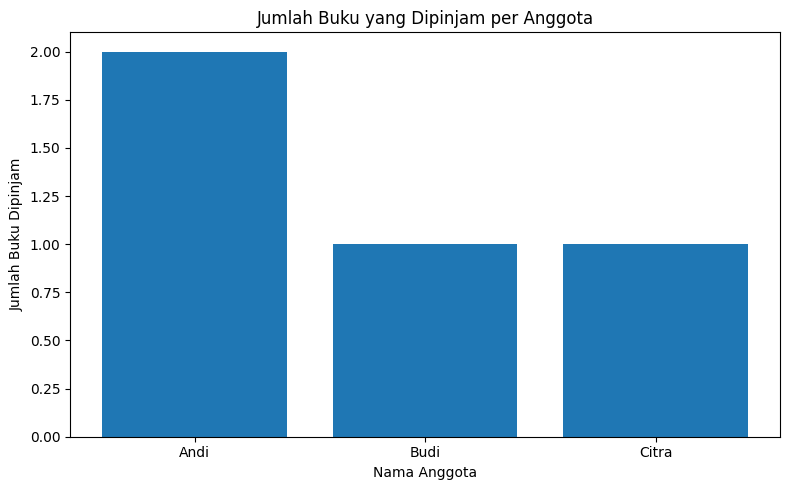

In [9]:
plt.figure(figsize=(8, 5))
plt.bar(df_rekap["nama_anggota"], df_rekap["jumlah_buku_dipinjam"])
plt.title("Jumlah Buku yang Dipinjam per Anggota")
plt.xlabel("Nama Anggota")
plt.ylabel("Jumlah Buku Dipinjam")
plt.tight_layout()
plt.show()

### 8.2 Histogram Durasi Peminjaman

Histogram dibuat hanya dari transaksi yang sudah dikembalikan karena transaksi yang masih berjalan belum memiliki durasi akhir.

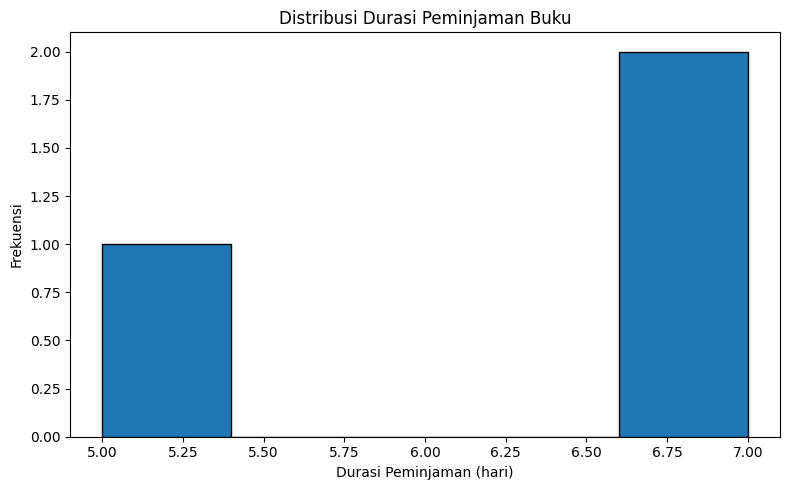

In [10]:
durasi_selesai = df_peminjaman["durasi_hari"].dropna()

plt.figure(figsize=(8, 5))
plt.hist(durasi_selesai, bins=5, edgecolor="black")
plt.title("Distribusi Durasi Peminjaman Buku")
plt.xlabel("Durasi Peminjaman (hari)")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

## 9. Kesimpulan

Berdasarkan praktik yang telah dilakukan:
1. Database perpustakaan berhasil dibuat menggunakan SQLite dengan tiga tabel: `buku`, `anggota`, dan `peminjaman`.
2. Lima data buku, tiga data anggota, dan empat transaksi peminjaman berhasil dimasukkan.
3. Query `JOIN` berhasil menampilkan daftar peminjaman beserta nama anggota dan judul buku.
4. Query `GROUP BY` dan `COUNT()` berhasil menghitung jumlah buku yang dipinjam oleh masing-masing anggota.
5. Hasil query diolah menggunakan pandas untuk menghitung durasi peminjaman dan status pengembalian.
6. Matplotlib digunakan untuk menampilkan diagram batang jumlah peminjaman per anggota dan histogram durasi peminjaman.

## 10. Menutup Koneksi Database

Jalankan cell ini setelah seluruh proses selesai.

In [11]:
conn.close()
print("Koneksi database berhasil ditutup.")

Koneksi database berhasil ditutup.
